# 04 · Expected-goals model — training data, validation, calibration

Logistic-regression xG trained on **StatsBomb open data** (8.8k shots, 351 matches) using only features a
single camera can observe at the moment of the shot: location, goal angle, goalkeeper position, opponents
in the shooting triangle and pressure. Validation is grouped by match (5-fold), and compared with StatsBomb's
own xG on the same shots (which also uses body part, technique and shot height).

Data: StatsBomb open data — https://github.com/statsbomb/open-data (attribution "Data: StatsBomb").

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
sys.path.insert(0, str(ROOT / "scripts"))
from train_xg import build_table, cv_eval, fit_lr
from football_eval.xg import XGModel, BASIC, FULL, feature_row, freeze_frame_features
from football_eval.pitch import Pitch, draw_pitch
shots_path = ROOT / "data/xg/shots_raw.jsonl"
df = build_table(shots_path)
model = XGModel.load(ROOT / "models/xg_model.json")
print(f"{len(df):,} shots | goal rate {df.goal.mean():.3f}")
df.groupby("type").agg(shots=("goal", "size"), goal_rate=("goal", "mean")).sort_values("shots", ascending=False)

8,800 shots | goal rate 0.120


,shots,goal_rate
type,,
Open Play,8152,0.104
Free Kick,365,0.044
Penalty,277,0.708
Corner,6,0.000


## Cross-validated performance (grouped by match)

In [2]:
op = df[df.type == "Open Play"].reset_index(drop=True)
res, preds = {}, {}
for name, feats in (("basic (dist+angle)", BASIC), ("full (+GK, defenders, pressure)", FULL)):
    m, p = cv_eval(op, feats); res[name] = m; preds[name] = p
sbm = op.dropna(subset=["sb_xg"])
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
res["StatsBomb xG (reference)"] = dict(auc=roc_auc_score(sbm.goal, sbm.sb_xg), brier=brier_score_loss(sbm.goal, sbm.sb_xg),
                                       logloss=log_loss(sbm.goal, sbm.sb_xg), mean_pred=sbm.sb_xg.mean(), goal_rate=sbm.goal.mean())
pd.DataFrame(res).T

,auc,brier,logloss,mean_pred,goal_rate
basic (dist+angle),0.735,0.085,0.299,0.104,0.104
"full (+GK, defenders, pressure)",0.780,0.080,0.281,0.104,0.104
StatsBomb xG (reference),0.810,0.076,0.265,0.101,0.104


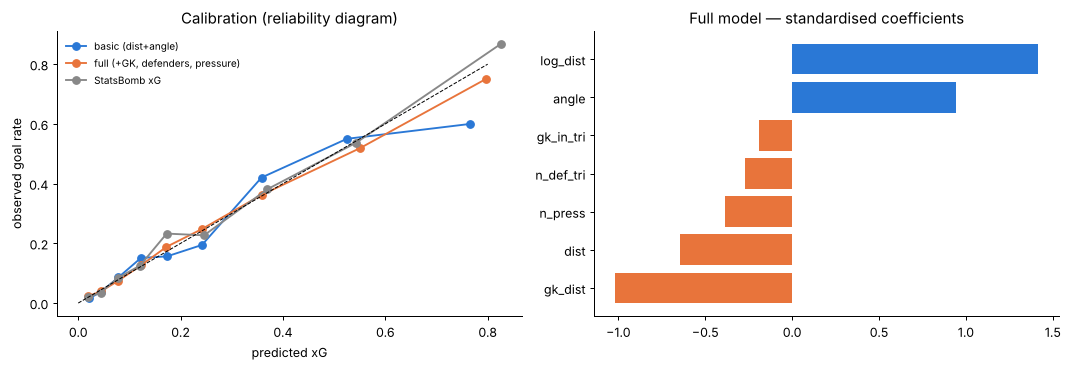

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.array([0, .03, .06, .1, .15, .2, .3, .45, .7, 1])
for (name, p), c in zip(list(preds.items()) + [("StatsBomb xG", op.sb_xg.to_numpy())], ["#2a78d6", "#e8743b", "#888888"]):
    b = np.digitize(p, bins) - 1
    cal = pd.DataFrame({"b": b, "p": p, "y": op.goal}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax[0].plot(cal.p, cal.y, "o-", c=c, label=name)
ax[0].plot([0, .8], [0, .8], "k--", lw=0.8); ax[0].set_xlabel("predicted xG"); ax[0].set_ylabel("observed goal rate")
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Calibration (reliability diagram)")
coef = pd.Series(model.p["full"]["coef"], index=model.p["full"]["features"]).sort_values()
ax[1].barh(coef.index, coef.values, color=["#e8743b" if v < 0 else "#2a78d6" for v in coef.values])
ax[1].set_title("Full model — standardised coefficients"); plt.tight_layout()

## xG surface (no defenders, goalkeeper on his line)

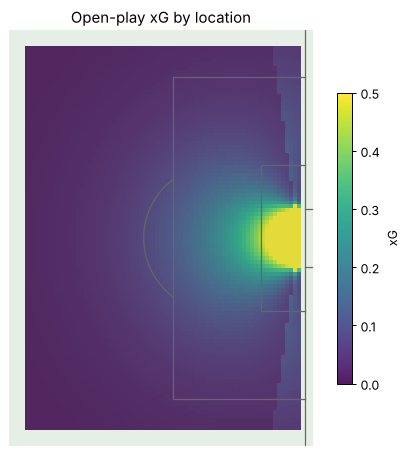

In [4]:
pitch = Pitch()
xs, ys = np.linspace(70, 104.5, 70), np.linspace(10, 58, 97)
Z = np.zeros((len(ys), len(xs)))
for i, y in enumerate(ys):
    rows = [feature_row(x, y, freeze_frame_features((x, y), np.zeros((0, 2)), (104.5, 34))) for x in xs]
    Z[i] = model.predict(rows, "full")
fig, ax = plt.subplots(figsize=(7, 6)); draw_pitch(ax, pitch, color="#666666")
im = ax.imshow(Z, extent=[xs[0], xs[-1], ys[-1], ys[0]], cmap="viridis", vmin=0, vmax=0.5, alpha=0.9, zorder=0)
ax.set_xlim(68, 106); ax.set_ylim(60, 8); plt.colorbar(im, ax=ax, shrink=0.7, label="xG")
ax.set_title("Open-play xG by location");

## Effect of the defensive situation (shot from the penalty spot, 11 m)

In [5]:
rows, labels = [], []
spot = (105 - 11, 34)
for n_def in (0, 1, 2, 3):
    opp = np.array([[spot[0] + 3 + k, 34 + (-1) ** k * 0.8 * k] for k in range(n_def)]).reshape(-1, 2)
    for gk_name, gk in (("GK on line", (104.6, 34)), ("GK off line (3 m)", (102.0, 34))):
        rows.append(feature_row(*spot, freeze_frame_features(spot, opp, gk))); labels.append((n_def, gk_name))
eff = pd.Series(model.predict(rows, "full"), index=pd.MultiIndex.from_tuples(labels, names=["defenders in triangle", "goalkeeper"])).unstack()
eff.round(3)

goalkeeper,GK off line (3 m),GK on line
defenders in triangle,,
0,0.267,0.200
1,0.213,0.156
2,0.167,0.121
3,0.130,0.093


## Notes for video use
* **Penalties** use a constant (empirical conversion in the training data); **direct free kicks** are scaled by
  the empirical ratio stored in `models/xg_model.json`.
* **Headers** cannot be told apart reliably from one wide camera, so the model is trained *without* body part:
  its predictions are averages over feet and headers for each situation.
* The geometric features come from the homography; an airborne ball is projected too far from the camera, but
  shots are taken at foot level, so the shot *location* (ball at the striker's foot) is well estimated.
* Retrain at any time with `python scripts/train_xg.py` (see the script header for re-downloading the data).